# 01 Data: the ideal forest and the arrival order

**Question.** Is the hand-made ideal forest well formed, and does its arrival order need every
outcome (a) to (e) at least once?

The prompts, the ideal forest and the arrival order are a **draft** by Claude Opus 5.5
(`claude-opus-5-5`, 25 Nov 2026) in `data/ideal_forest.yaml`. The group reviews them for realism
before any result is reported. The intended outcome per step is a design intention, not a test.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import viz
from forest.ip import ACTIONS, Params, load_config
from forest.model import load_ideal

cfg = load_config(ROOT / "config.yaml")
P = Params.from_config(cfg)
ideal = load_ideal()
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

## The ideal forest
Topics above `U` get a red border, topics below `L` a dashed one.

session nn_exercise_sheet: 25 prompts, 2 groups, 4 trees, 10 topics, max depth 3 levels; topics above U=5: ['Backpropagation']


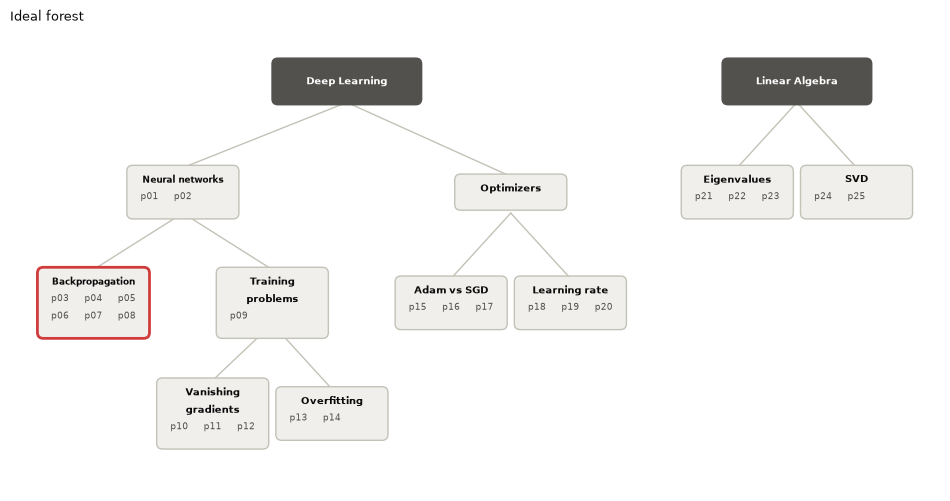

In [2]:
F = ideal.forest
print(f"session {ideal.session}: {len(F.prompts)} prompts, {len(F.groups)} groups, {len(F.roots())} trees, "
      f"{len(F.topics)} topics, max depth {max(F.depth(t) for t in F.topics) + 1} levels; "
      f"topics above U={P.U}: {[F.topics[t].label for t in F.topics if len(F.prompts_in(t)) > P.U]}")
fig, ax = plt.subplots(figsize=(12, 6))
viz.draw_forest(F, ax, P=P, title="Ideal forest")
fig.savefig(FIG / "01_ideal_forest.png", dpi=150, bbox_inches="tight")
plt.show()

## The arrival order and the intended outcome per step

In [3]:
arrival = pd.DataFrame([{"step": i, "prompt": p, "intended": ideal.intended[p][0], "why": ideal.intended[p][1],
                         "ideal topic": F.path(ideal.topic_of(p))} for i, p in enumerate(ideal.arrival, 1)])
arrival

,step,prompt,intended,why,ideal topic
0,1,p01,d,first prompt: new group Deep Learning with the tree Neural networks,Deep Learning > Neural networks
1,2,p03,b,"Backpropagation, a branch under Neural networks",Deep Learning > Neural networks > Backpropagation
2,3,p04,a,Backpropagation,Deep Learning > Neural networks > Backpropagation
3,4,p02,a,Neural networks,Deep Learning > Neural networks
4,5,p05,a,Backpropagation,Deep Learning > Neural networks > Backpropagation
5,6,p10,b,vanishing gradients after several backprop prompts: a new branch,Deep Learning > Neural networks > Training problems > Vanishing gradients
6,7,p15,c,first optimizer prompt: a new tree,Deep Learning > Optimizers > Adam vs SGD
7,8,p13,b,"overfitting, before Training problems is obvious",Deep Learning > Neural networks > Training problems > Overfitting
8,9,p06,a,Backpropagation,Deep Learning > Neural networks > Backpropagation
9,10,p11,a,vanishing gradients,Deep Learning > Neural networks > Training problems > Vanishing gradients


In [4]:
counts = arrival["intended"].value_counts().reindex(list("abcde"), fill_value=0)
print({f"({a}) {ACTIONS[a]}": int(n) for a, n in counts.items()})
assert (counts > 0).all(), "every outcome must be needed at least once"

{'(a) add': 16, '(b) new branch': 3, '(c) new tree': 2, '(d) new group': 2, '(e) restructure': 2}


## The ideal forest after the first arrival steps
What the ideal forest looks like with only the prompts that have arrived so far: a check that the
order makes sense.

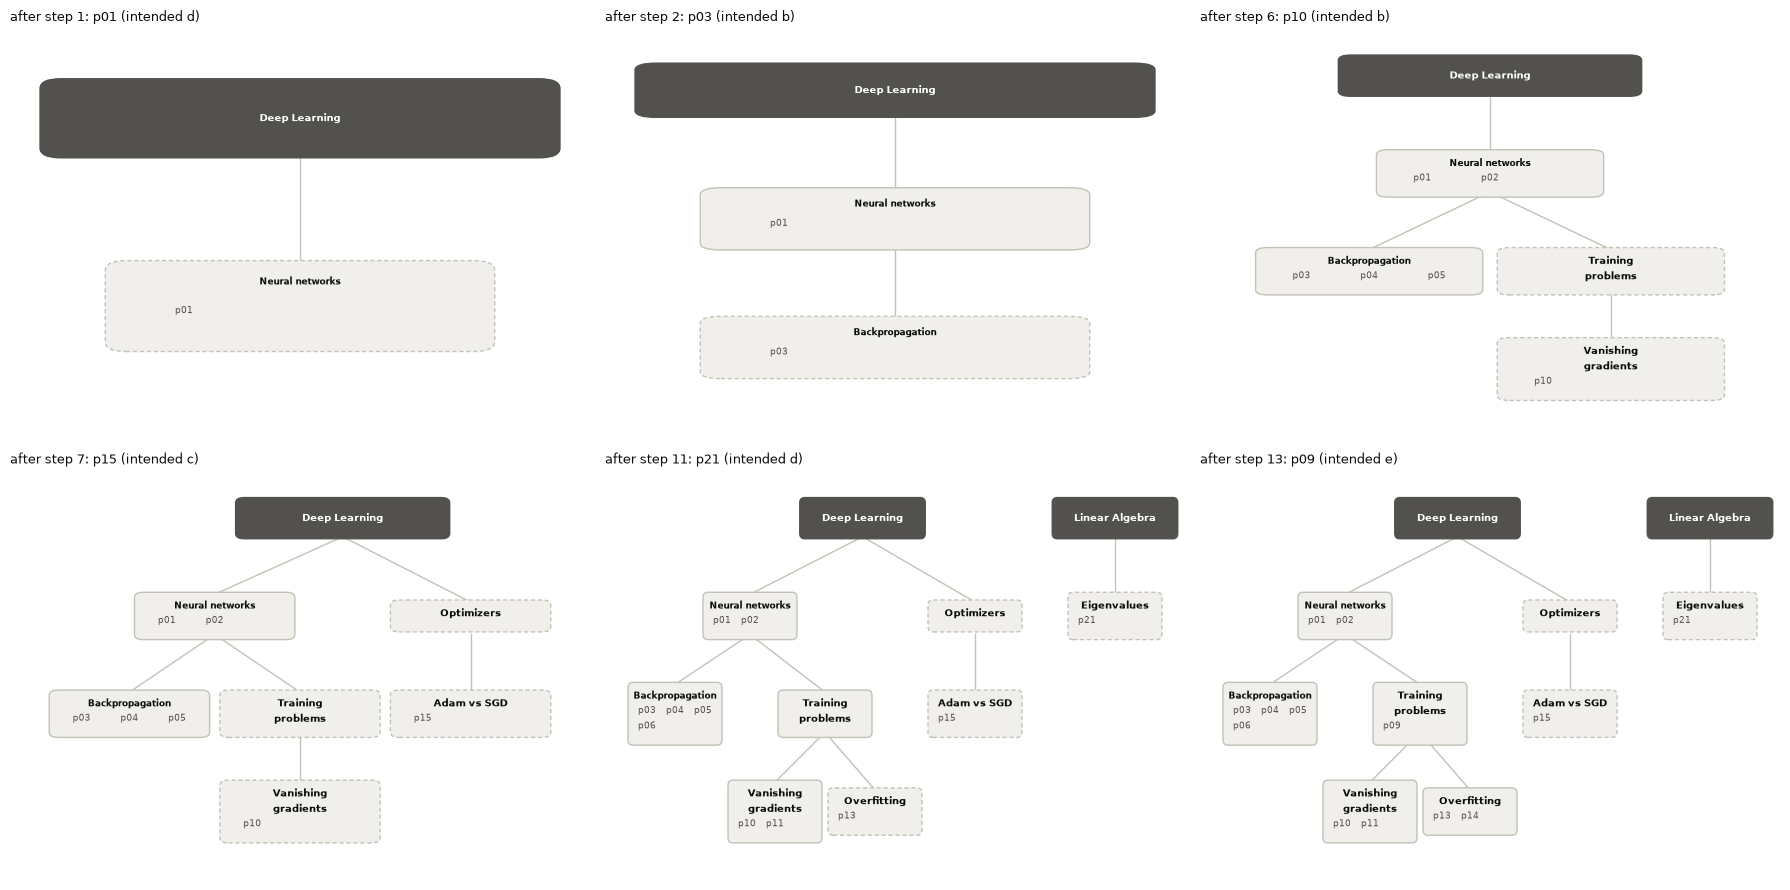

In [5]:
steps = [1, 2, 6, 7, 11, 13]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, k in zip(axes.flat, steps):
    p = ideal.arrival[k - 1]
    viz.draw_forest(ideal.upto(k), ax, P=P, title=f"after step {k}: {p} (intended {ideal.intended[p][0]})")
fig.tight_layout()
fig.savefig(FIG / "01_ideal_first_steps.png", dpi=130, bbox_inches="tight")
plt.show()

## Invalid forests fail with a clear message

In [6]:
from forest.model import ForestError, Topic

bad = F.copy()
bad.topics["t_neural_networks"].parent, bad.topics["t_neural_networks"].parent_kind = "t_backpropagation", "topic"
try:
    bad.validate(P.D)
except ForestError as e:
    print("cycle:\n  " + "\n  ".join(e.problems))
bad = F.copy()
bad.topics["t_empty"] = Topic("t_empty", "Empty topic", "g_deep_learning", "group", 1.0)
try:
    bad.validate(P.D)
except ForestError as e:
    print("empty topic:\n  " + "\n  ".join(e.problems))

cycle:
  topic t_neural_networks ('Neural networks') is on a cycle
  topic t_backpropagation ('Backpropagation') is on a cycle
  topic t_training_problems ('Training problems') is on a cycle
  topic t_vanishing_gradients ('Vanishing gradients') is on a cycle
  topic t_overfitting ('Overfitting') is on a cycle
empty topic:
  topic t_empty ('Empty topic') is empty


## Findings

- The ideal forest validates: 25 prompts, 2 groups, 4 trees, 10 topics, 3 levels deep.
  Backpropagation holds 6 prompts, above `U = 5`, as the plan asks.
- The arrival order needs every outcome: intended (a) 16 times, (b) 3, (c) 2, (d) 2, (e) 2.
- The snapshots of the first steps grow as designed: Neural networks first, then Backpropagation as a
  branch, vanishing gradients and the first optimizer prompt before Training problems exists, and
  Linear Algebra at step 11.
- A cycle and an empty topic fail validation with messages that name the topics. On a cycle, every
  topic below it is reported too.
- *For the group:* review the prompts and the arrival order (draft).